# 1. 数据读取

In [45]:
import pandas as pd
import numpy as np
import xgboost as xgb

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    roc_auc_score, average_precision_score,
    f1_score, precision_score, recall_score,
    confusion_matrix, accuracy_score
)

df = pd.read_csv('data/processed_data.csv')
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])

df = df[df['Quantity'] > 0].copy()

df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalPrice,cancelled
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30,False
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,False
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00,False
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,False
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,False


# 2. 客户特征和数据集划分

In [46]:
analysis_date = df['InvoiceDate'].max() + pd.Timedelta(days=1)
reference_date = analysis_date - pd.Timedelta(days=90)

valid = df.loc[~df['cancelled']]
history = valid.loc[valid['InvoiceDate'] <= reference_date]
future = valid.loc[valid['InvoiceDate'] > reference_date]

data = history.groupby('CustomerID').agg(
    LastPurchaseDate=('InvoiceDate', 'max'),
    OrderCount=('InvoiceNo', 'nunique'),
    TotalSpend=('TotalPrice', 'sum'),
    TotalQuantity=('Quantity', 'sum')
).reset_index()

data['Recency'] = (reference_date - data.pop('LastPurchaseDate')).dt.days
data['AvgOrderValue'] = data['TotalSpend'] / data['OrderCount']
data['AvgItemsPerOrder'] = data['TotalQuantity'] / data['OrderCount']
data['future_purchase'] = data['CustomerID'].isin(future['CustomerID']).astype(int)

train_df, temp_df = train_test_split(data, test_size=0.30, random_state=42, stratify=data['future_purchase'])
val_df, test_df = train_test_split(temp_df, test_size=0.50, random_state=42, stratify=temp_df['future_purchase'])

data.head()

,CustomerID,OrderCount,TotalSpend,TotalQuantity,Recency,AvgOrderValue,AvgItemsPerOrder,future_purchase
0,12346,1,77183.60,74215,236,77183.600000,74215.0,0
1,12347,5,2790.86,1590,40,558.172000,318.0,1
2,12348,3,1487.24,2124,159,495.746667,708.0,1
3,12350,1,334.40,197,220,334.400000,197.0,0
4,12352,5,1561.81,254,172,312.362000,50.8,1


# 3. 基于直接聚合特征预测用户未来90天复购情况

In [47]:
target = 'future_purchase'

# 两种特征共用训练和评估步骤
def train_and_evaluate(feature_cols):
    X_train = train_df[feature_cols]
    y_train = train_df[target].astype(int)
    X_val = val_df[feature_cols]
    y_val = val_df[target].astype(int)

    model = xgb.XGBClassifier(
        n_estimators=1000,
        learning_rate=0.05,
        max_depth=6,
        subsample=0.8,
        colsample_bytree=0.8,
        eval_metric='auc',
        early_stopping_rounds=50,
        random_state=42,
        tree_method='hist'
    )
    model.fit(
        X_train, y_train,
        eval_set=[(X_val, y_val)],
        verbose=False
    )

    results = {}
    for name, frame in [('验证集', val_df), ('测试集', test_df)]:
        y_true = frame[target].astype(int)
        y_score = model.predict_proba(frame[feature_cols])[:, 1]
        y_pred = (y_score >= 0.5).astype(int)
        results[name] = {
            'Accuracy': accuracy_score(y_true, y_pred),
            'AUC': roc_auc_score(y_true, y_score),
            'PR-AUC': average_precision_score(y_true, y_score),
            'F1': f1_score(y_true, y_pred, zero_division=0),
            'Precision': precision_score(y_true, y_pred, zero_division=0),
            'Recall': recall_score(y_true, y_pred, zero_division=0),
            'Confusion Matrix': confusion_matrix(y_true, y_pred, labels=[0, 1])
        }

    for name, metrics in results.items():
        print(f'\n{name}')
        for metric in ['Accuracy', 'AUC', 'PR-AUC', 'F1', 'Precision', 'Recall']:
            print(f'{metric}: {metrics[metric]:.4f}')
        print(metrics['Confusion Matrix'])
    return model, results

In [48]:
direct_features = ['TotalSpend', 'OrderCount', 'AvgOrderValue','TotalQuantity', 'AvgItemsPerOrder']
model_direct, metrics_direct = train_and_evaluate(direct_features)


验证集
Accuracy: 0.5870
AUC: 0.7225
PR-AUC: 0.7939
F1: 0.7324
Precision: 0.5801
Recall: 0.9931
[[ 11 207]
 [  2 286]]

测试集
Accuracy: 0.5700
AUC: 0.7338
PR-AUC: 0.7998
F1: 0.7212
Precision: 0.5709
Recall: 0.9792
[[  7 212]
 [  6 282]]


# 4. 基于RFM特征预测用户未来90天复购情况

In [49]:
score_sources = {
    'R_Score': 'Recency',
    'F_Score': 'OrderCount',
    'M_Score': 'TotalSpend'
}
for score, source in score_sources.items():
    cuts = np.unique(train_df[source].quantile([0.2, 0.4, 0.6, 0.8]))
    for frame in [train_df, val_df, test_df]:
        values = np.searchsorted(cuts, frame[source], side='right') + 1
        frame[score] = 6 - values if score == 'R_Score' else values

rfm_features = direct_features + ['Recency', 'R_Score', 'F_Score', 'M_Score']
model_rfm, metrics_rfm = train_and_evaluate(rfm_features)


验证集
Accuracy: 0.6324
AUC: 0.7470
PR-AUC: 0.8188
F1: 0.7297
Precision: 0.6275
Recall: 0.8715
[[ 69 149]
 [ 37 251]]

测试集
Accuracy: 0.6548
AUC: 0.7500
PR-AUC: 0.8144
F1: 0.7415
Precision: 0.6452
Recall: 0.8715
[[ 81 138]
 [ 37 251]]


# 5. 两个模型效果的对比

验证集


,直接聚合特征,RFM特征
Accuracy,0.5870,0.6324
AUC,0.7225,0.7470
PR-AUC,0.7939,0.8188
F1,0.7324,0.7297
Precision,0.5801,0.6275
Recall,0.9931,0.8715


测试集


,直接聚合特征,RFM特征
Accuracy,0.5700,0.6548
AUC,0.7338,0.7500
PR-AUC,0.7998,0.8144
F1,0.7212,0.7415
Precision,0.5709,0.6452
Recall,0.9792,0.8715


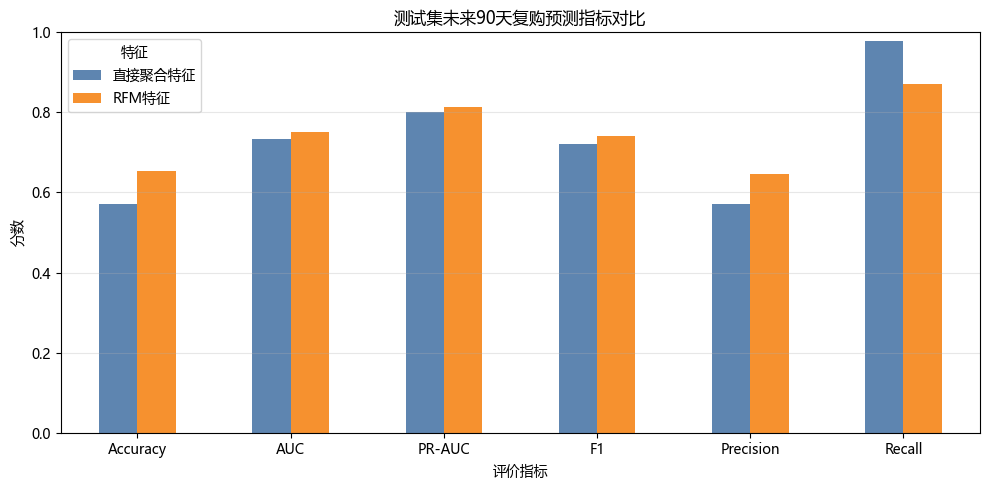

In [50]:
import matplotlib.pyplot as plt

plt.rcParams['font.sans-serif'] = ['Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False

metric_names = ['Accuracy', 'AUC', 'PR-AUC', 'F1', 'Precision', 'Recall']
comparison_tables = {}
for split in ['验证集', '测试集']:
    comparison_tables[split] = pd.DataFrame({
        '直接聚合特征': [metrics_direct[split][name] for name in metric_names],
        'RFM特征': [metrics_rfm[split][name] for name in metric_names]
    }, index=metric_names)
    print(split)
    display(comparison_tables[split].round(4))

comparison = comparison_tables['测试集']

ax = comparison.plot(
    kind='bar',
    figsize=(10, 5),
    ylim=(0, 1),
    color=['#4C78A8', '#F58518'],
    alpha=0.9
)
ax.set_title('测试集未来90天复购预测指标对比')
ax.set_ylabel('分数')
ax.set_xlabel('评价指标')
ax.legend(title='特征')
ax.grid(axis='y', alpha=0.3)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

结合 AUC、PR-AUC 和固定 0.5 阈值下的分类指标评价两种特征。指标变化表示增加 Recency 和评分后的整体效果，单次划分不能证明统计显著性。